In [1]:
#@title Load Data Train, Validation, dan TF-IDF Vectorizer
import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

train_df = pd.read_csv("./data/processed/train.csv")
val_df = pd.read_csv("./data/processed/val.csv")

# Load TF-IDF Vectorizer pada train_df
tfidf = joblib.load("./models/tfidf_vectorizer.joblib")

# Transform teks ke fitur TF-IDF
X_train = tfidf.transform(train_df["clean_text"].fillna(""))
y_train = train_df["label"].values

X_val = tfidf.transform(val_df["clean_text"].fillna(""))
y_val = val_df["label"].values

print("Ukuran X_train:", X_train.shape)
print("Ukuran X_val  :", X_val.shape)

Ukuran X_train: (8446, 5000)
Ukuran X_val  : (1056, 5000)


In [2]:
#@title Latih Baseline Model

mulai = time.time()
# alpha=1.0 adalah Laplace Smoothing standar
model_baseline = MultinomialNB(alpha=1.0, fit_prior=True)
model_baseline.fit(X_train, y_train)
waktu_training = time.time() - mulai

print(f"Model Multinomial Naive Bayes selesai dilatih dalam {waktu_training:.4f} detik.")

# Simpan model baseline untuk tahap evaluasi akhir di Minggu 6
joblib.dump(model_baseline, "./models/model_nb_baseline.joblib")

Model Multinomial Naive Bayes selesai dilatih dalam 0.0130 detik.


['./models/model_nb_baseline.joblib']

In [3]:
#@title Evaluasi pada Data Training dan Validation

y_train_pred = model_baseline.predict(X_train)
y_val_pred = model_baseline.predict(X_val)

print("=== HASIL PADA TRAINING SET ===")
print(f"Accuracy : {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Precision: {precision_score(y_train, y_train_pred):.4f}")
print(f"Recall   : {recall_score(y_train, y_train_pred):.4f}")
print(f"F1-Score : {f1_score(y_train, y_train_pred):.4f}")

print("\n=== HASIL PADA VALIDATION SET ===")
print(f"Accuracy : {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred):.4f}")
print(f"F1-Score : {f1_score(y_val, y_val_pred):.4f}")

print("\nClassification Report (Validation Set):")
print(classification_report(y_val, y_val_pred, digits=4))

=== HASIL PADA TRAINING SET ===
Accuracy : 0.9092
Precision: 0.9618
Recall   : 0.8175
F1-Score : 0.8838

=== HASIL PADA VALIDATION SET ===
Accuracy : 0.8693
Precision: 0.9400
Recall   : 0.7377
F1-Score : 0.8266

Classification Report (Validation Set):
              precision    recall  f1-score   support

           0     0.8343    0.9656    0.8951       610
           1     0.9400    0.7377    0.8266       446

    accuracy                         0.8693      1056
   macro avg     0.8871    0.8516    0.8609      1056
weighted avg     0.8789    0.8693    0.8662      1056



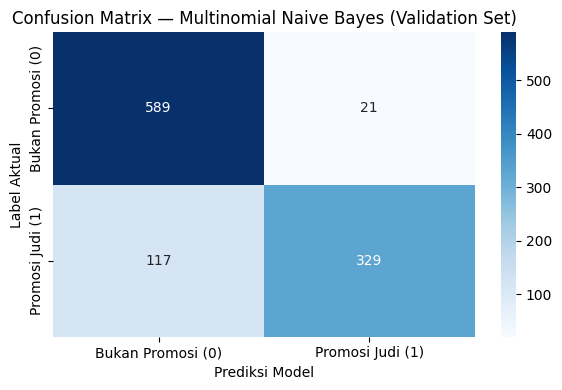

In [4]:
#@title Confusion matrix (Validasi)
cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Bukan Promosi (0)", "Promosi Judi (1)"],
    yticklabels=["Bukan Promosi (0)", "Promosi Judi (1)"]
)
plt.title("Confusion Matrix — Multinomial Naive Bayes (Validation Set)")
plt.xlabel("Prediksi Model")
plt.ylabel("Label Aktual")
plt.tight_layout()
plt.show()